In [18]:
import pandas as pd
from glob import glob
import re
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import json
import torch
import numpy as np
from bbox_annotation import Annotation, annotation_from_json
from sklearn.model_selection import train_test_split

from tool import crop_rgb

In [19]:
np.random.seed(0)

In [20]:
Image.MAX_IMAGE_PIXELS = None

In [21]:
image_pattern = re.compile(r"(.*)\.([^\.]*)")

In [22]:
data = []

In [23]:
for i in glob("dataset/images/*"):
    name = Path(i).stem

    annotation_file = Path("dataset/bbox_annotation").joinpath(f"{name}.json")

    try:
        with open(annotation_file, "r") as annotation_file:
            annotation: Annotation = annotation_from_json(json.load(annotation_file))
    except FileNotFoundError as e:
        print(f"{annotation_file} not found, skipping")
        continue

    image = Image.open(i)

    if image.width != annotation["width"] or image.height != annotation["height"]:
        print(f"{annotation_file} has w: {annotation["width"]} h: {annotation["height"]}, but image has dimension w: {annotation["width"]} h: {annotation["height"]}, skipping")
        continue

    data.append({
        "Name": name,
        "Image": image,
        "Image Width": image.width,
        "Image Height": image.height,
        "Depth Column": annotation["bounding_boxs"]["depth_column"],
        "Interpreted Lithology Column": annotation["bounding_boxs"]["interpreted_lithology_column"],
        "Lithology Legend": annotation["bounding_boxs"]["lithology_legend"],
    })

data

dataset/bbox_annotation/60811406050000_608114060500_g31765 001 st00 bp00__master log_5640-28740_5 in_md(1).json not found, skipping


[{'Name': '60811405800000_608114058000_g16786_001_00_00_md5_mud_show_2',
  'Image': <PIL.TiffImagePlugin.TiffImageFile image mode=RGB size=1534x2600>,
  'Image Width': 1534,
  'Image Height': 2600,
  'Depth Column': [275, 1576, 355, 2575],
  'Interpreted Lithology Column': [1165, 1576, 1228, 2575],
  'Lithology Legend': [2, 599, 1532, 1002]},
 {'Name': '60807402860000_gb506#2_md_mudlog',
  'Image': <PIL.TiffImagePlugin.TiffImageFile image mode=RGB size=1536x9623>,
  'Image Width': 1536,
  'Image Height': 9623,
  'Depth Column': [236, 1206, 316, 9623],
  'Interpreted Lithology Column': [953, 1206, 1000, 9623],
  'Lithology Legend': [12, 596, 1525, 1003]},
 {'Name': '0000000009_d-582_0000020435-0001_log07_chromatograph_ratio',
  'Image': <PIL.TiffImagePlugin.TiffImageFile image mode=1 size=4864x12031>,
  'Image Width': 4864,
  'Image Height': 12031,
  'Depth Column': [1278, 4387, 1369, 11175],
  'Interpreted Lithology Column': [1357, 4387, 1606, 11175],
  'Lithology Legend': [1938, 1513,

In [24]:
data_df = pd.DataFrame(data)
data_df

,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend
0,60811405800000_608114058000_g16786_001_00_00_m...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1534,2600,"[275, 1576, 355, 2575]","[1165, 1576, 1228, 2575]","[2, 599, 1532, 1002]"
1,60807402860000_gb506#2_md_mudlog,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1536,9623,"[236, 1206, 316, 9623]","[953, 1206, 1000, 9623]","[12, 596, 1525, 1003]"
2,0000000009_d-582_0000020435-0001_log07_chromat...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,12031,"[1278, 4387, 1369, 11175]","[1357, 4387, 1606, 11175]","[1938, 1513, 3030, 2655]"
3,0000000009_d-582_0000020435-0001_log05_chromat...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,13051,"[1285, 4381, 1376, 12182]","[1364, 4381, 1612, 12182]","[1937, 1513, 3029, 2655]"
4,0000000009_d-582_0000020435-0001_log09_chromat...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,10000,"[1247, 4388, 1337, 9146]","[1326, 4388, 1574, 9146]","[1907, 1513, 2999, 2655]"
5,60818400650000_at0574_4_neptune_1inch_tvdmudlo...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,2307,36050,"[450, 2699, 508, 36050]","[1763, 2699, 1856, 36050]","[3, 1154, 2305, 1732]"
6,0000000009_d-582_0000020435-0001_log04_fe_5in_md,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,13041,"[1272, 4384, 1364, 12184]","[2976, 4384, 3226, 12184]","[1924, 1513, 3016, 2655]"
7,0000000009_d-582_0000020435-0001_log08_fe_5in_md,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,10007,"[1266, 4390, 1355, 9149]","[2969, 4390, 3217, 9149]","[1925, 1513, 3017, 2655]"
8,0000000009_d-582_0000020435-0001_log02_fe_5in_md,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,12035,"[1270, 4387, 1358, 11180]","[2974, 4387, 3220, 11180]","[1925, 1513, 3017, 2655]"
9,0000000009_d-582_0000020435-0001_log06_fe_5in_md,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,12050,"[1288, 4404, 1376, 11195]","[2991, 4404, 3237, 11195]","[1943, 1513, 3035, 2655]"


In [25]:
training_dataset, rest = train_test_split(data_df, test_size=0.3, random_state=0)
validation_dataset, testing_dataset = train_test_split(rest, test_size=0.5, random_state=0)

display(training_dataset)
display(validation_dataset)
display(testing_dataset)

,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend
14,60812400810000_ocs-g 16987 003 st00bp00_1inmd_...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,2200,18800,"[510, 1297, 619, 17855]","[1673, 1297, 1716, 17855]","[59, 613, 1606, 1012]"
46,60811407570000_bp_gc743_15607_dc802_st00bp00_m...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,110000,"[485, 1543, 536, 109291]","[1303, 1543, 1355, 109291]","[447, 499, 1211, 1145]"
18,60817411400100_mc761_1_st1_mudlog_1md_17133_22886,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,15400,"[340, 2859, 383, 14459]","[1290, 2859, 1369, 14459]","[0, 1295, 1223, 1884]"
48,MC765_P011_ST00BP00_5inchTVD_Depth_MudLog_3686...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,134200,"[377, 1623, 448, 132811]","[1134, 1623, 1171, 132811]","[79, 904, 1621, 1327]"
42,Rio_Nueces_3744_Unit_1_222_5IN_MUD,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,125400,"[280, 6861, 321, 123365]","[661, 6861, 731, 123365]","[34, 3299, 1667, 3644]"
15,60817411400100_mc761_1_st1_mudlog_1tvd_17129_2...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1275,8250,"[255, 2197, 288, 8198]","[938, 2197, 995, 8198]","[0, 972, 918, 1400]"
31,60817410140100_mc822#10bp01 1-240 tvd mud log,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1534,163220,"[236, 1205, 316, 163204]","[953, 1205, 1000, 163204]","[2, 594, 1532, 1000]"
30,60818400600100_608184006001_g08037_002_01_00_5...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1534,67200,"[275, 1575, 355, 66978]","[1165, 1575, 1228, 66978]","[2, 599, 1532, 1002]"
16,Shell_08852_KE001_ST01BP00_1inTVD_MudLog_17564...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1653,9356,"[450, 1550, 540, 6832]","[540, 1550, 600, 6832]","[40, 891, 1612, 1127]"
43,60811405800300_mdn-1_st01bp01_5 inch tvdmudlog...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1275,120450,"[265, 1185, 325, 119853]","[932, 1185, 980, 119853]","[60, 452, 1210, 768]"


,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend
33,60812401020000_xom_ocs-g_20351_ju103_st00bp00_...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,209000,"[355, 1576, 426, 208873]","[1198, 1576, 1255, 208873]","[79, 600, 1615, 1005]"
32,60817412840000_mc_776_6_ml_mudlog_5757_23721_5...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1552,182200,"[276, 1575, 355, 182078]","[1167, 1575, 1230, 182078]","[2, 599, 1535, 1001]"
7,0000000009_d-582_0000020435-0001_log08_fe_5in_md,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,10007,"[1266, 4390, 1355, 9149]","[2969, 4390, 3217, 9149]","[1925, 1513, 3017, 2655]"
41,Rio_Nueces_3744_Unit_1_212_MUD_5IN,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,121000,"[280, 6861, 321, 120865]","[661, 6861, 731, 120865]","[34, 3299, 1667, 3644]"
22,MC765_P011_ST00BP01_5inchMD_Depth_MudLog_18230...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,35200,"[377, 1623, 448, 33669]","[1134, 1623, 1171, 33669]","[79, 904, 1621, 1327]"
29,60811405800100_mdn-1_st00bp01_5 inch tvdmudlog...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1534,187600,"[275, 1575, 355, 187576]","[1165, 1575, 1228, 187576]","[2, 599, 1532, 1002]"
28,608114075800 - Allegheny Attic GC297 #3 OCS-G ...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1700,26400,"[362, 2737, 395, 24270]","[1263, 2737, 1323, 24270]","[477, 590, 1060, 1144]"
27,60811405350100_shenzi-sb203-st00bp01_mudlog_43...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,2550,72600,"[535, 2363, 655, 71702]","[1875, 2363, 1970, 71702]","[122, 898, 2432, 1505]"


,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend
11,0000000009_d-582_0000020435-0001_log01_fe_1in_md,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,93524,"[1271, 4392, 1407, 92668]","[2972, 4392, 3269, 92668]","[1988, 1513, 3080, 2655]"
45,Mudlog-Trail Mtn1Palisades,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1650,62325,"[391, 1424, 414, 62325]","[335, 1424, 391, 62325]","[75, 691, 673, 1215]"
26,60811405800500_608114058005_g16786_001_03_00_t...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1534,192600,"[275, 1575, 355, 192576]","[1165, 1575, 1228, 192576]","[2, 599, 1532, 1002]"
4,0000000009_d-582_0000020435-0001_log09_chromat...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,10000,"[1247, 4388, 1337, 9146]","[1326, 4388, 1574, 9146]","[1907, 1513, 2999, 2655]"
35,60811406050000_608114060500_g31765 001 st00 bp...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1680,238000,"[278, 1628, 343, 233912]","[1167, 1628, 1230, 233912]","[2, 600, 1538, 1021]"
2,0000000009_d-582_0000020435-0001_log07_chromat...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,12031,"[1278, 4387, 1369, 11175]","[1357, 4387, 1606, 11175]","[1938, 1513, 3030, 2655]"
10,0000000009_d-582_0000020435-0001_log03_chromat...,<PIL.TiffImagePlugin.TiffImageFile image mode=...,4864,12031,"[1268, 4386, 1356, 11178]","[1346, 4386, 1593, 11178]","[1923, 1513, 3015, 2655]"
34,Critter Creek 202-1807H_Mud_Vertical_PDF.pdf,<PIL.TiffImagePlugin.TiffImageFile image mode=...,1275,44550,"[277, 5480, 338, 43356]","[817, 5480, 893, 43356]","[28, 2302, 1248, 2563]"


In [27]:
data_df.loc[0]

Name                            60811405800000_608114058000_g16786_001_00_00_m...
Image                           <PIL.TiffImagePlugin.TiffImageFile image mode=...
Image Width                                                                  1534
Image Height                                                                 2600
Depth Column                                               [275, 1576, 355, 2575]
Interpreted Lithology Column                             [1165, 1576, 1228, 2575]
Lithology Legend                                             [2, 599, 1532, 1002]
Name: 0, dtype: object

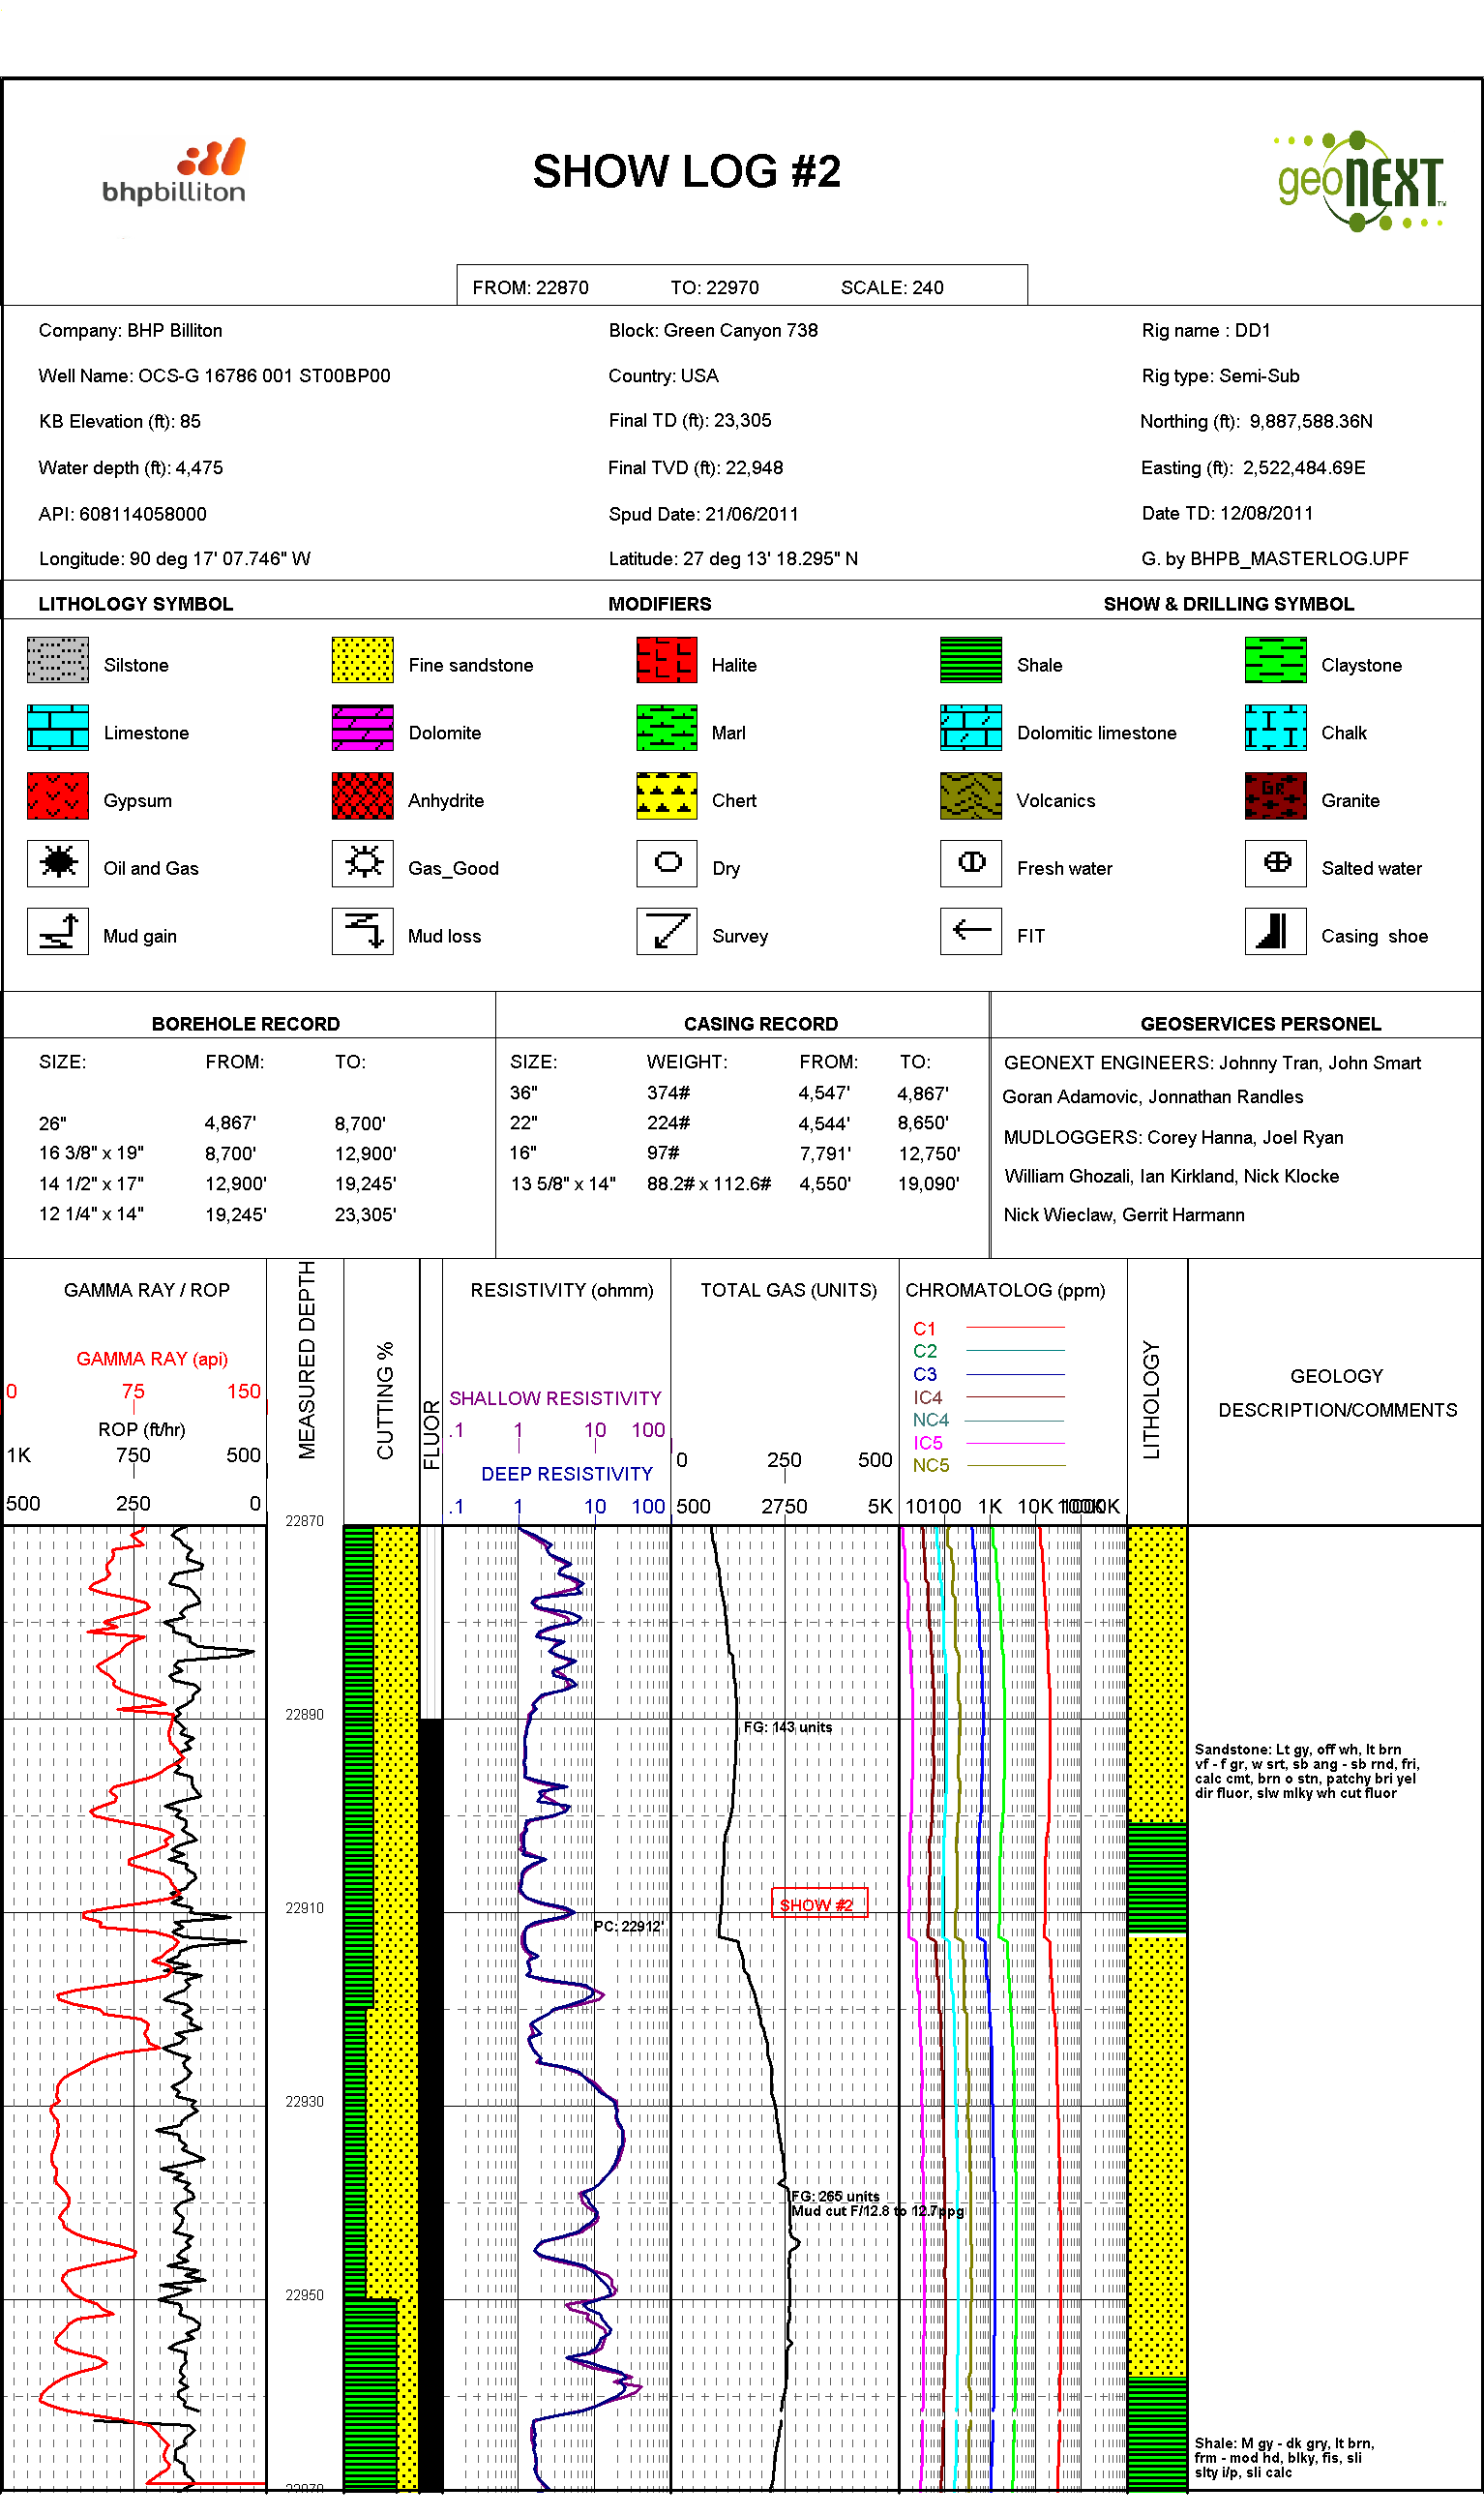

In [28]:
data_df.loc[0]["Image"]

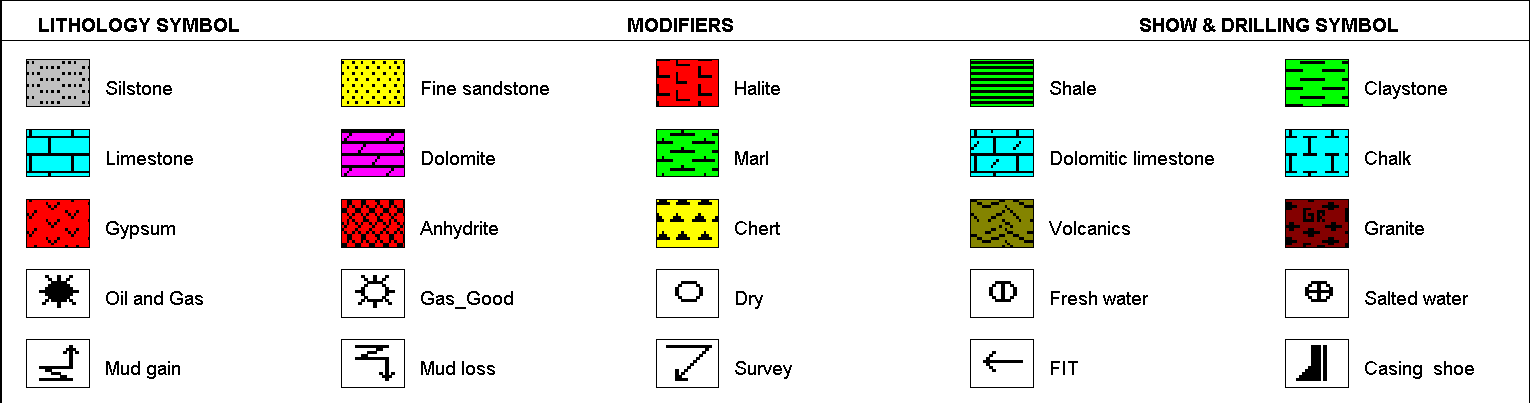

In [29]:
crop_rgb(data_df.loc[0]["Image"], data_df.loc[0]["Lithology Legend"])